# v11: overfit one fixed 40-task Wu sample at lambda = 0, 1, 4 (see train-beta-v11-overfit-fixed-sample-800m.md)

In [3]:
import math
import os
import sys
from pathlib import Path
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# Walk up from the notebook folder to locate the repository's `code/` root
CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "models"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and models/ at or above {Path.cwd()}")

# The `beta_ols` package (and this notebook's other modules) is in `src/` next to this notebook
EXPLORATION_DIR = CODE_DIR / "papers" / "beta-loss" / "exploration"
SRC_DIR = EXPLORATION_DIR / "src"
if not (SRC_DIR / "beta_ols").is_dir():
    raise RuntimeError(f"`beta_ols` package not found in {SRC_DIR}")

# Run from `code/` and expose `code/`, `code/kev/`, and `src/` on sys.path
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(SRC_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from dataclasses import replace

from models.kev_pointer import KevPointerModel
from training import free_gpu

import beta_ols
from beta_train.config import TrainConfig, scale_lr_for_sample_size
from beta_train.items import build_items_cached, items_summary
from beta_train.model_state import snapshot_trainable
from beta_train.trainer import RunResult, run_training
from beta_train.validation import PopulationValidator, validate_all_cached, validation_metrics_frame

# Disk cache for training items and the untrained (step-0) validation; delete the folder to clear it
CACHE_DIR = CODE_DIR / ".cache" / "beta_training"

print(f"CODE_DIR: {CODE_DIR}")

CODE_DIR: /home/dw/github/decision-models-finetuning/code


In [4]:
# Require CUDA and release any previously loaded `kev_model` before allocating a fresh 800M backbone
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required to run jaredpalmer/kev-0.8b in bf16 train mode")
if "kev_model" in globals():
    globals().pop("kev_model")
device = "cuda"
free_gpu()
torch.manual_seed(42)

# Model settings (also the key of the cached step-0 validation)
KEV_BASE = "jaredpalmer/kev-0.8b"
LORA_RANK = 64
WEIGHTS_DTYPE = "bf16"
HEAD_TEMPERATURE = 1.0   # training uses raw uncalibrated temperature = 1.0

# Build the frozen backbone + LoRA + pointer head
t_model0 = time.perf_counter()
kev_model = KevPointerModel.build(
    KEV_BASE,
    device=device,
    lora_rank=LORA_RANK,
    weights_dtype=WEIGHTS_DTYPE,
)
kev_model.net.head.temperature = HEAD_TEMPERATURE
kev_model.train()                     # enable training mode (LoRA dropout active, trainable params require_grad)
torch.cuda.synchronize()
model_load_sec = time.perf_counter() - t_model0

trainable_params_count = sum(p.numel() for p in kev_model.trainable_parameters())
total_params_count = sum(p.numel() for p in kev_model.parameters())
display(
    pd.Series(
        {
            "base_model": KEV_BASE,
            "mode": kev_model.mode,
            "training": kev_model.training,
            "weights_dtype": kev_model.meta.weights_dtype,
            "lora_rank": kev_model.meta.lora,
            "trainable_params": f"{trainable_params_count:,}",
            "total_params": f"{total_params_count:,}",
            "model_load_sec": round(model_load_sec, 3),
        },
        name="kev_800m_train_mode",
    ).to_frame()
)

# Snapshot the untrained trainable weights right after building, so every run, diagnostic, and the step-0
# validation start from them (rebuilding the model re-snapshots)
INIT_TRAINABLE_STATE = snapshot_trainable(kev_model)
MODEL_KEY = {"base": KEV_BASE, "lora_rank": LORA_RANK, "weights_dtype": WEIGHTS_DTYPE, "head_temperature": HEAD_TEMPERATURE}
print(f"Snapshotted {len(INIT_TRAINABLE_STATE)} trainable tensors")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,kev_800m_train_mode
base_model,jaredpalmer/kev-0.8b
mode,lora_rank 64
training,True
weights_dtype,bf16
lora_rank,64
trainable_params,"43,815,424"
total_params,"796,208,448"
model_load_sec,1.721


Snapshotted 376 trainable tensors


# Fixed sample

In [13]:
# The fixed sample: FIXED_SAMPLE_SIZE Wu tasks drawn once; every training step of every run uses exactly these tasks
DATASET = "wu2025"
FIXED_SAMPLE_SIZE = 160    # tasks, the v10 sample size
FIXED_SAMPLE_SEED = 0

dataset_module = beta_ols.DATASET_MODULES[DATASET]
full_choice_df = dataset_module.load_choice_df()

# Regression specs from the full data (sigma = full-data outcome SD, the same standardization training uses)
full_rows = dataset_module.regression_rows(full_choice_df)
full_specs = dataset_module.regression_specs(full_rows)

# Draw the tasks, then keep them in the data's order (each respondent's tasks stay in prompt order)
sample_rng = np.random.default_rng(FIXED_SAMPLE_SEED)
drawn_positions = sample_rng.choice(len(full_choice_df), size=FIXED_SAMPLE_SIZE, replace=False)
drawn_positions = np.sort(drawn_positions)
fixed_choice_df = full_choice_df.iloc[drawn_positions].reset_index(drop=True)
print(f"fixed sample: {len(fixed_choice_df)} tasks from {fixed_choice_df['CASEID'].nunique()} respondents")

fixed sample: 160 tasks from 155 respondents


# Validator and training items

In [14]:
# Validator on the fixed sample itself: its KL and its beta error (the model's betas vs the sample's own human OLS
# betas), in eval mode (no LoRA dropout), with the full-data sigma
VALIDATION_MAX_QUESTIONS = 1024
VALIDATION_MAX_CHARS = 1_000_000
validators = {
    DATASET: PopulationValidator(
        dataset_module,
        fixed_choice_df,
        full_specs,
        max_questions=VALIDATION_MAX_QUESTIONS,
        max_chars=VALIDATION_MAX_CHARS,
    )
}
display(pd.DataFrame([validator.describe() for validator in validators.values()]).set_index("validator"))

# Untrained (step-0) validation of the fixed sample, from the disk cache when it already ran
step0_validation, step0_cache_report = validate_all_cached(
    kev_model,
    validators,
    INIT_TRAINABLE_STATE,
    model_key=MODEL_KEY,
    cache_dir=CACHE_DIR,
)
display(step0_cache_report)
display(validation_metrics_frame(step0_validation).round(4))
for validator_name, (_, beta_df) in step0_validation.items():
    display(beta_df.round(4))

,kind,tasks,packed_persona_states,regressions,max_questions,max_chars,prep_sec
validator,,,,,,,
wu2025,fused,160,155,wu2025,1024,1000000,0.139


Tokenizing wu2025_validation:   0%|          | 0/155 [00:00<?, ?state/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

,source
validator,
wu2025,computed


,wu2025
kl_loss,0.9893
beta_mse,0.0331
beta_mae,0.1619
beta_mape_pct,130.0493
spearman_rho,0.1429
eval_prep_sec,0.0550
eval_gpu_sec,0.9517
eval_wall_sec,2.1855
eval_ms_per_task,13.6594


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
Monthly bill: $110 vs $105,wu2025,-0.1600,0.0353,0.1954,0.1954
Monthly bill: $115 vs $105,wu2025,-0.1897,0.0701,0.2597,0.2597
Monthly bill: $120 vs $105,wu2025,-0.3341,-0.1312,0.2029,0.2029
Monthly bill: $125 vs $105,wu2025,-0.2672,-0.0952,0.1720,0.1720
Percentage of renewables: 30% vs 10%,wu2025,0.1264,-0.0398,-0.1662,0.1662
Percentage of renewables: 50% vs 10%,wu2025,0.0694,0.0450,-0.0244,0.0244
Percentage of renewables: 100% vs 10%,wu2025,0.0114,-0.0198,-0.0312,0.0312
Locally produced renewables: Yes vs No,wu2025,0.1122,-0.1310,-0.2433,0.2433


In [15]:
# Training items of the fixed sample (one per task), the same rows the validator scores
fixed_items, items_cache_report = build_items_cached(
    kev_model, {DATASET: dataset_module}, {DATASET: fixed_choice_df}, cache_dir=CACHE_DIR
)
display(items_cache_report)
specs_by_dataset = {DATASET: full_specs}
display(items_summary(fixed_items, specs_by_dataset))
if len(fixed_items[DATASET]) != FIXED_SAMPLE_SIZE:
    raise ValueError(f"expected {FIXED_SAMPLE_SIZE} items, got {len(fixed_items[DATASET])}")

items: wu2025:   0%|          | 0/160 [00:00<?, ?it/s]

,items (rows),source
dataset,,
wu2025,160,built


,items (rows),respondents,regression_groups
dataset,,,
wu2025,160,155,wu2025


# Train

In [16]:
# Run folders: one per run under RUNS_DIR
NOTEBOOK = "train-beta-v11-overfit-fixed-sample-800m"
RUNS_DIR = EXPLORATION_DIR / "runs" / NOTEBOOK
BEST_METRIC = f"{DATASET}/beta_mse"
BEST_MODE = "min"

# One sample per epoch (sample size = all items), so an epoch is one step and every step sees the same 40 tasks
OVERFIT_STEPS = 300
# Constant LR = v10's peak LR at S = 40; no weight decay; clipping as in v10
BASE_LR_PER_TASK = 2e-5 / math.sqrt(10)
MICRO_CHUNK = 16          # v10's micro chunk (fits Wu's worst-case chunk)
EVAL_EVERY_STEPS = 10
GRADIENT_SPLIT = True     # log the CE and lambda x beta gradient norms every step

BASE_CONFIG = TrainConfig(
    train_datasets=(DATASET,),
    sample_size_by_dataset={DATASET: FIXED_SAMPLE_SIZE},
    beta_lambda=0.0,
    lr=scale_lr_for_sample_size(BASE_LR_PER_TASK, FIXED_SAMPLE_SIZE),
    num_epochs=OVERFIT_STEPS,
    eval_every_by_validator={DATASET: EVAL_EVERY_STEPS},
    lr_schedule="constant",
    weight_decay=0.0,
    micro_chunk=MICRO_CHUNK,
    gradient_checkpointing=False,
    grad_clip=1.0,
    seed=42,
    gradient_split=GRADIENT_SPLIT,
)


def run_name(config: TrainConfig) -> str:
    # Run folder name from the setting this notebook varies (lambda) and the fixed ones
    return f"lambda={config.beta_lambda:g}_lr={config.lr:g}_S={FIXED_SAMPLE_SIZE}_steps={config.num_epochs}"


# Settings recorded in each run's run.json (not used by training)
RUN_METADATA = {
    "notebook": NOTEBOOK,
    "model": MODEL_KEY,
    "dataset": DATASET,
    "fixed_sample_size": FIXED_SAMPLE_SIZE,
    "fixed_sample_seed": FIXED_SAMPLE_SEED,
    "fixed_sample_caseids": list(fixed_choice_df["CASEID"]),
    "fixed_sample_qids": [str(qid) for qid in fixed_choice_df["qid"]],
    "base_lr_per_task": BASE_LR_PER_TASK,
}
runs: dict[str, RunResult] = {}
display(pd.Series(BASE_CONFIG.as_dict(), name="base_config").to_frame())

,base_config
train_datasets,[wu2025]
sample_size_by_dataset,{'wu2025': 160}
beta_lambda,0.0
lr,0.00008
num_epochs,300
eval_every_by_validator,{'wu2025': 10}
lr_schedule,constant
weight_decay,0.0
micro_chunk,16
gradient_checkpointing,False


,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,lr,wu2025/eval_wall_sec,train_elapsed_sec,mean grad_ce_norm,mean grad_beta_norm,mean grad_lambda_beta_norm,mean grad_total_norm,mean grad_cos_ce_lambda_beta
step,,,,,,,,,,,,,,,,,,
0,0,0,NaN,0.98935,0.13237,0.98935,0.03309,0.16188,130.04928,0.14286,NaN,2.18550,0.00000,NaN,NaN,NaN,NaN,NaN
10,10,1600,0.65173,0.39133,0.00443,0.39133,0.00111,0.02725,73.67840,0.97619,0.00008,2.22146,54.47040,5.24129,1.90642,0.00000,5.24129,NaN
20,20,3200,0.15879,0.08097,0.00019,0.08097,0.00005,0.00462,7.70743,0.97619,0.00008,2.20413,108.88678,6.48981,0.76084,0.00000,6.48981,NaN
30,30,4800,0.02561,0.00121,0.00000,0.00121,0.00000,0.00074,2.53100,1.00000,0.00008,2.11063,162.81095,4.97336,0.17968,0.00000,4.97336,NaN
40,40,6400,0.01429,0.02180,0.00051,0.02180,0.00013,0.00823,20.22452,1.00000,0.00008,2.14624,216.78390,7.09637,0.20551,0.00000,7.09637,NaN
50,50,8000,0.02508,0.00074,0.00000,0.00074,0.00000,0.00037,0.88968,1.00000,0.00008,2.21333,271.05829,12.57370,0.34309,0.00000,12.57370,NaN
60,60,9600,0.01071,0.00912,0.00081,0.00912,0.00020,0.01190,21.82164,1.00000,0.00008,2.13576,325.04697,9.98054,0.50897,0.00000,9.98054,NaN
70,70,11200,0.02013,0.02929,0.00021,0.02929,0.00005,0.00484,20.70479,1.00000,0.00008,2.09353,379.00018,13.96942,0.41421,0.00000,13.96942,NaN
80,80,12800,0.00907,0.00077,0.00000,0.00077,0.00000,0.00070,0.73416,1.00000,0.00008,2.12080,433.28888,5.60228,0.22931,0.00000,5.60228,NaN


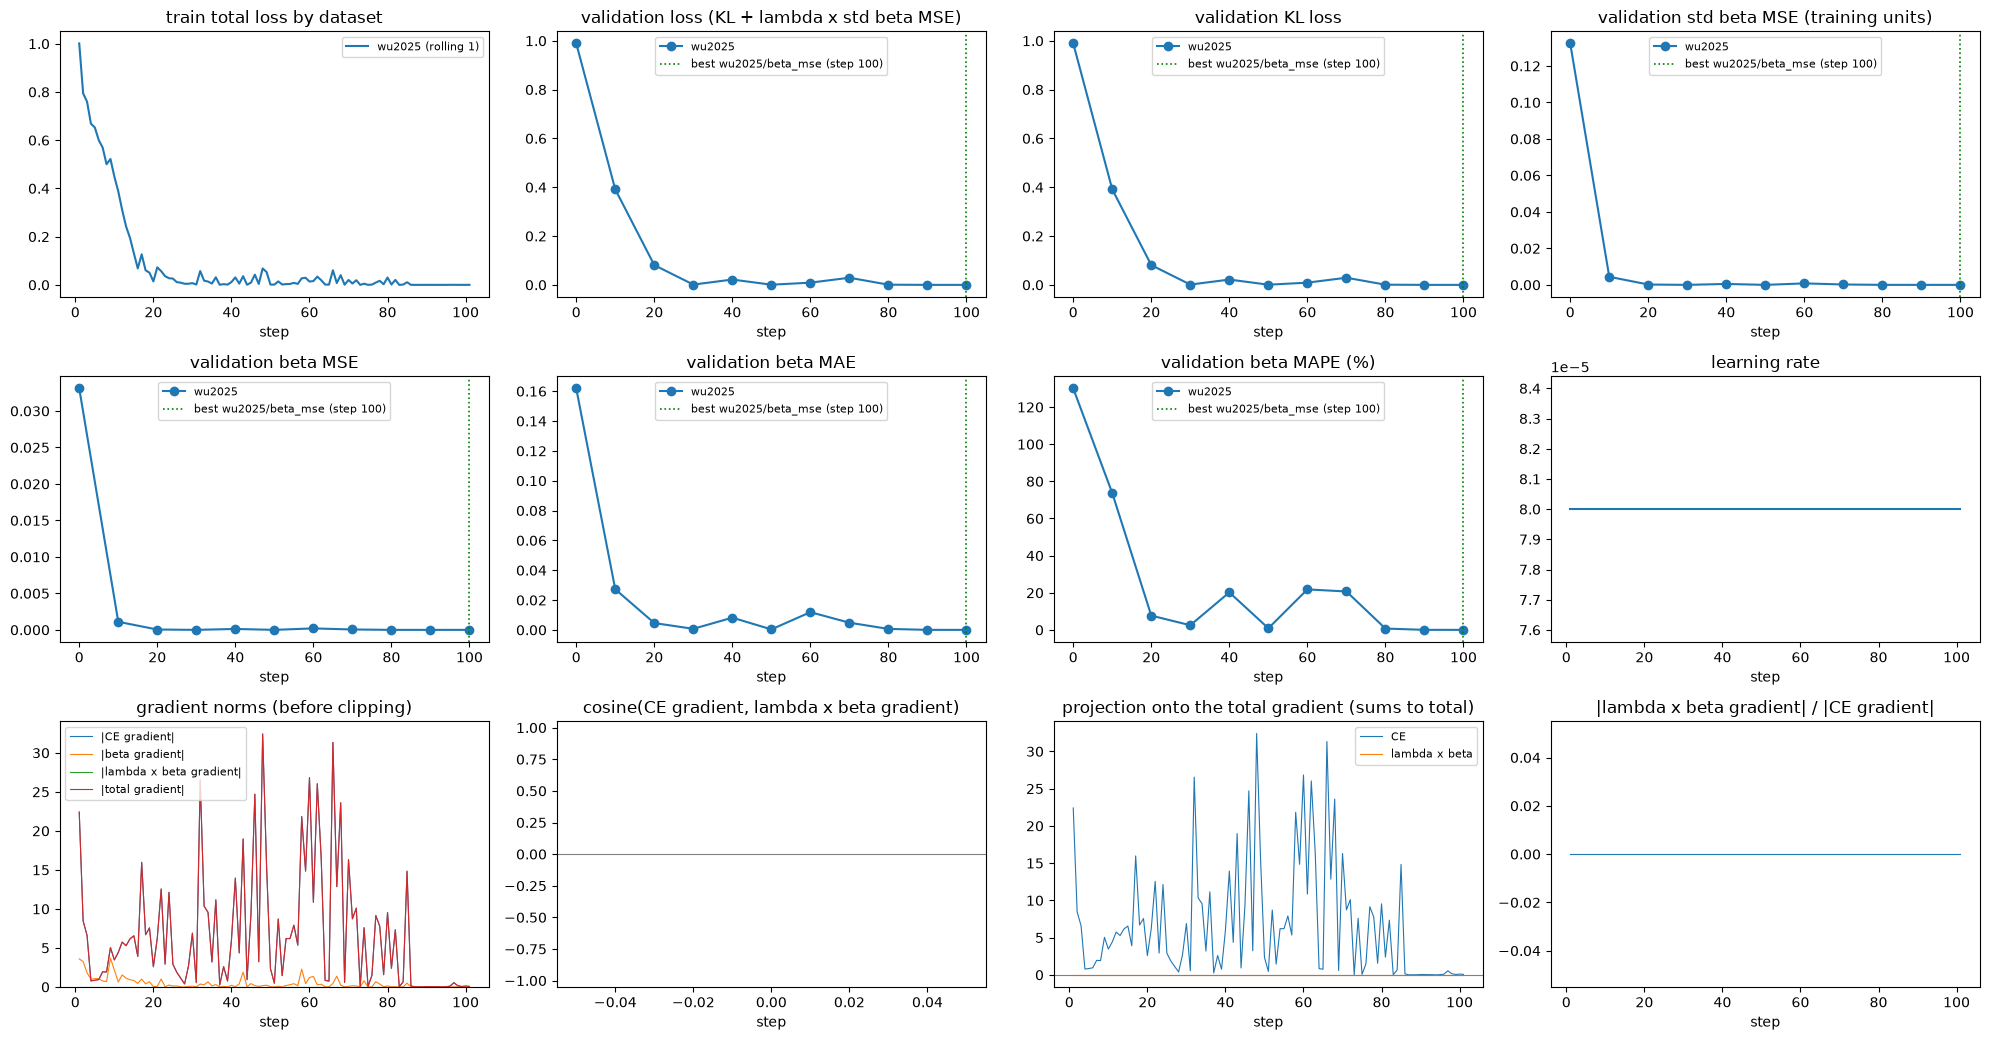

wu2025 | lambda=0:   0%|          | 0/300 [00:00<?, ?it/s]

pass 1 (forward): 0it [00:00, ?it/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

... (3 outputs left out)

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

KeyboardInterrupt: 

In [17]:
beta_lambda = 0.0
run_config = replace(BASE_CONFIG, beta_lambda=beta_lambda)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=fixed_items,
    specs_by_dataset=specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,lr,wu2025/eval_wall_sec,train_elapsed_sec,mean grad_ce_norm,mean grad_beta_norm,mean grad_lambda_beta_norm,mean grad_total_norm,mean grad_cos_ce_lambda_beta
step,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.12171,0.13237,0.98935,0.03309,0.16188,130.04928,0.14286,NaN,2.18550,0.00000,NaN,NaN,NaN,NaN,NaN
10,10,1600,0.67201,0.40046,0.00467,0.39579,0.00117,0.02728,43.87388,1.00000,0.00008,2.12320,53.99437,5.21392,1.45950,1.45950,6.10258,0.53226
20,20,3200,0.19225,0.03002,0.00010,0.02993,0.00002,0.00394,5.09682,1.00000,0.00008,2.14536,107.97485,17.43063,1.06254,1.06254,17.28668,0.28453
30,30,4800,0.05796,0.00058,0.00000,0.00058,0.00000,0.00021,0.28329,1.00000,0.00008,2.00080,162.12683,23.71637,1.40538,1.40538,24.91384,0.68605
40,40,6400,0.02718,0.05326,0.00144,0.05181,0.00036,0.01651,25.08102,1.00000,0.00008,1.97377,216.02334,19.67231,0.26738,0.26738,19.90153,0.68703
50,50,8000,0.03760,0.00337,0.00004,0.00333,0.00001,0.00246,7.67067,1.00000,0.00008,1.98630,270.18690,11.31421,0.50436,0.50436,11.65590,0.69175
60,60,9600,0.00999,0.02496,0.00025,0.02472,0.00006,0.00638,8.13993,1.00000,0.00008,2.14470,324.10182,3.78940,0.16931,0.16931,3.90666,0.77163
70,70,11200,0.01453,0.03348,0.00012,0.03336,0.00003,0.00329,3.49189,1.00000,0.00008,2.11923,378.01736,5.92525,0.15880,0.15880,6.04353,0.73319
80,80,12800,0.01900,0.00034,0.00000,0.00034,0.00000,0.00063,0.82172,1.00000,0.00008,2.13942,432.27669,5.80950,0.20866,0.20866,5.98326,0.84034


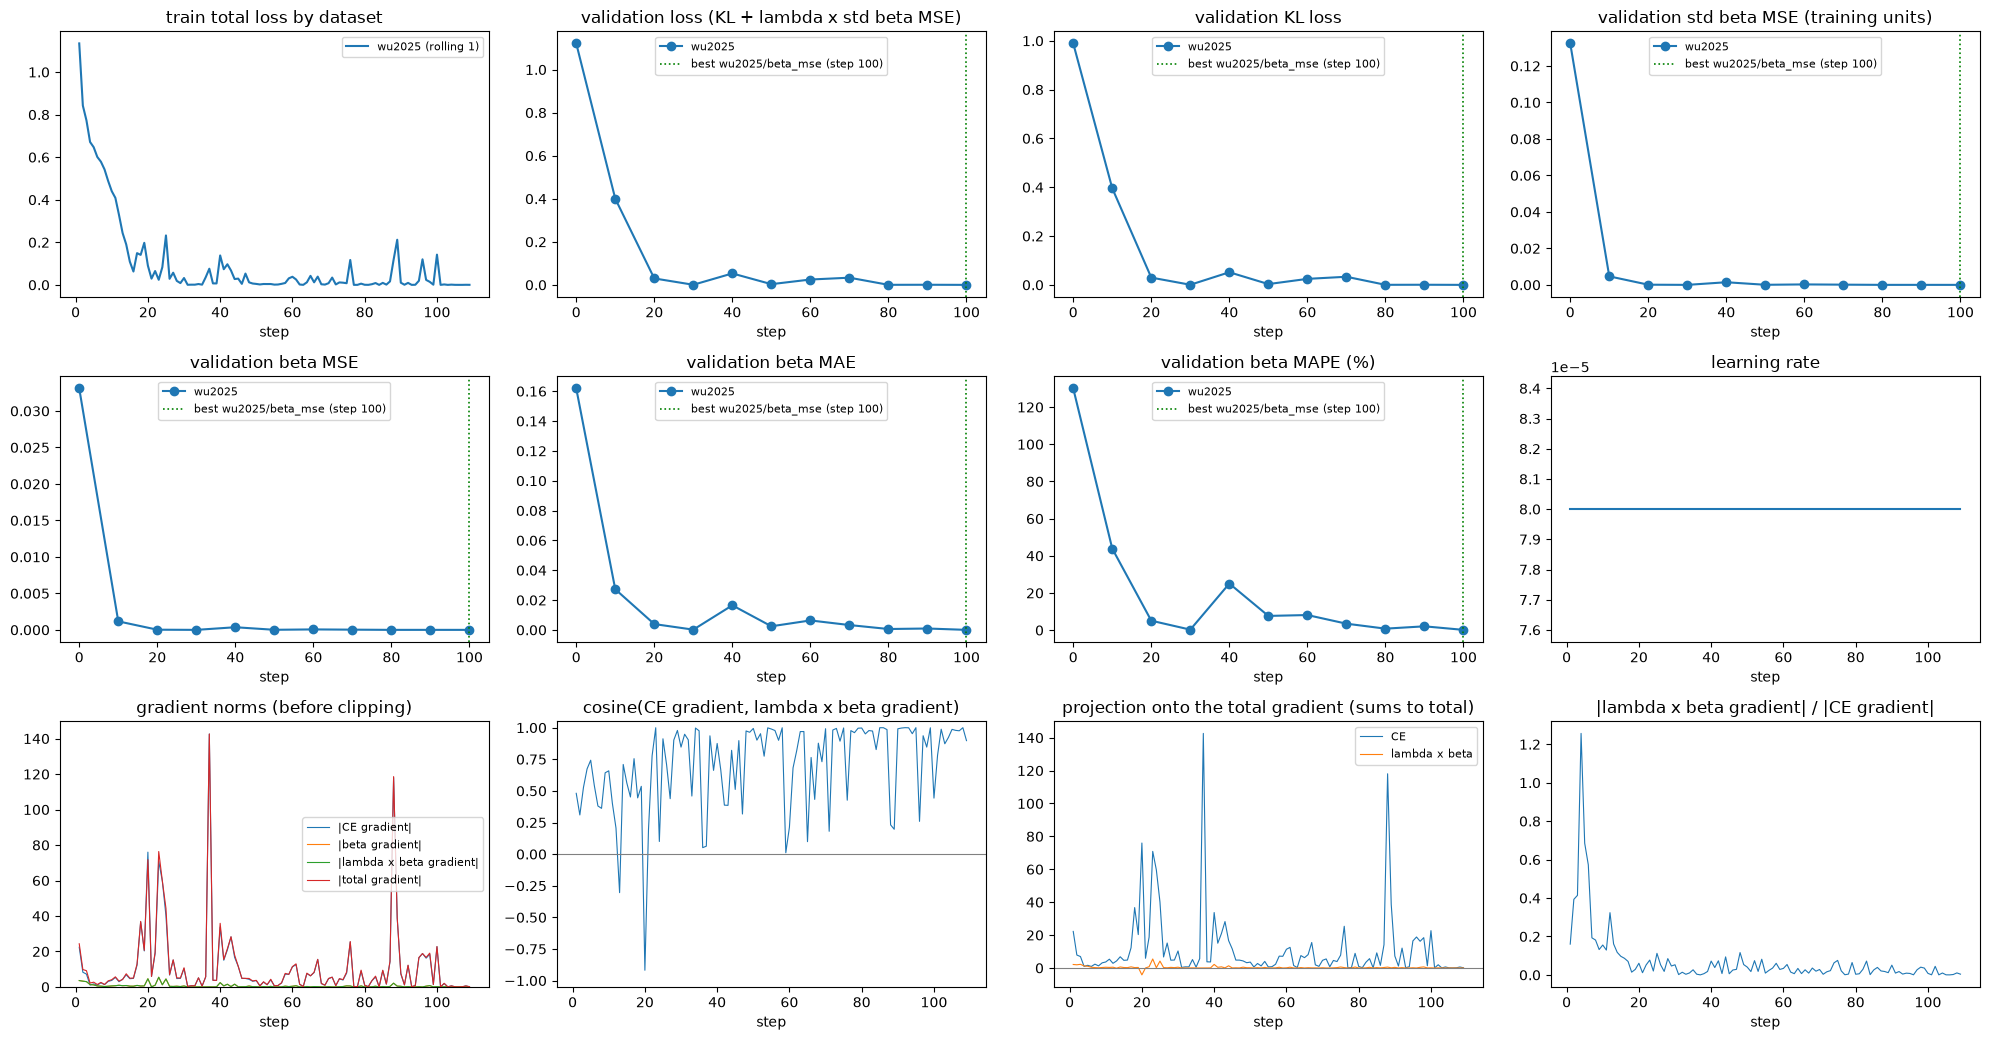

wu2025 | lambda=1:   0%|          | 0/300 [00:00<?, ?it/s]

pass 1 (forward): 0it [00:00, ?it/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

... (4 outputs left out)

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

KeyboardInterrupt: 

In [18]:
beta_lambda = 1.0
run_config = replace(BASE_CONFIG, beta_lambda=beta_lambda)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=fixed_items,
    specs_by_dataset=specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,lr,wu2025/eval_wall_sec,train_elapsed_sec,mean grad_ce_norm,mean grad_beta_norm,mean grad_lambda_beta_norm,mean grad_total_norm,mean grad_cos_ce_lambda_beta
step,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.51881,0.13237,0.98935,0.03309,0.16188,130.04928,0.14286,NaN,2.18550,0.00000,NaN,NaN,NaN,NaN,NaN
10,10,1600,0.81947,0.55478,0.01033,0.51347,0.00258,0.03962,29.75447,0.88095,0.00008,2.33361,54.36180,4.46276,1.32416,5.29662,8.43451,0.52281
20,20,3200,0.38529,0.09208,0.00025,0.09109,0.00006,0.00717,9.21520,1.00000,0.00008,2.27743,108.77379,2.03094,0.36659,1.46635,2.96324,0.38286
30,30,4800,0.02953,0.00022,0.00000,0.00021,0.00000,0.00012,0.10985,1.00000,0.00008,2.40754,163.20856,4.61636,0.22426,0.89703,5.36155,0.73412
40,40,6400,0.11442,0.00706,0.00004,0.00690,0.00001,0.00225,3.67272,1.00000,0.00008,2.42714,217.28737,27.84623,0.65416,2.61666,29.63431,0.62377
50,50,8000,0.03864,0.02753,0.00074,0.02456,0.00019,0.01059,13.19649,0.97619,0.00008,2.30754,271.67795,15.29869,0.44438,1.77750,16.66199,0.66072
60,60,9600,0.02934,0.03004,0.00097,0.02616,0.00024,0.01384,23.95960,1.00000,0.00008,2.35248,325.57962,9.48185,0.22012,0.88049,10.15227,0.70645
70,70,11200,0.00858,0.00234,0.00004,0.00217,0.00001,0.00266,5.99553,1.00000,0.00008,2.31058,379.54953,4.01755,0.15619,0.62474,4.61852,0.95534
80,80,12800,0.00716,0.00100,0.00000,0.00099,0.00000,0.00087,1.57028,1.00000,0.00008,2.33332,433.52616,3.69710,0.09596,0.38384,4.06872,0.91329


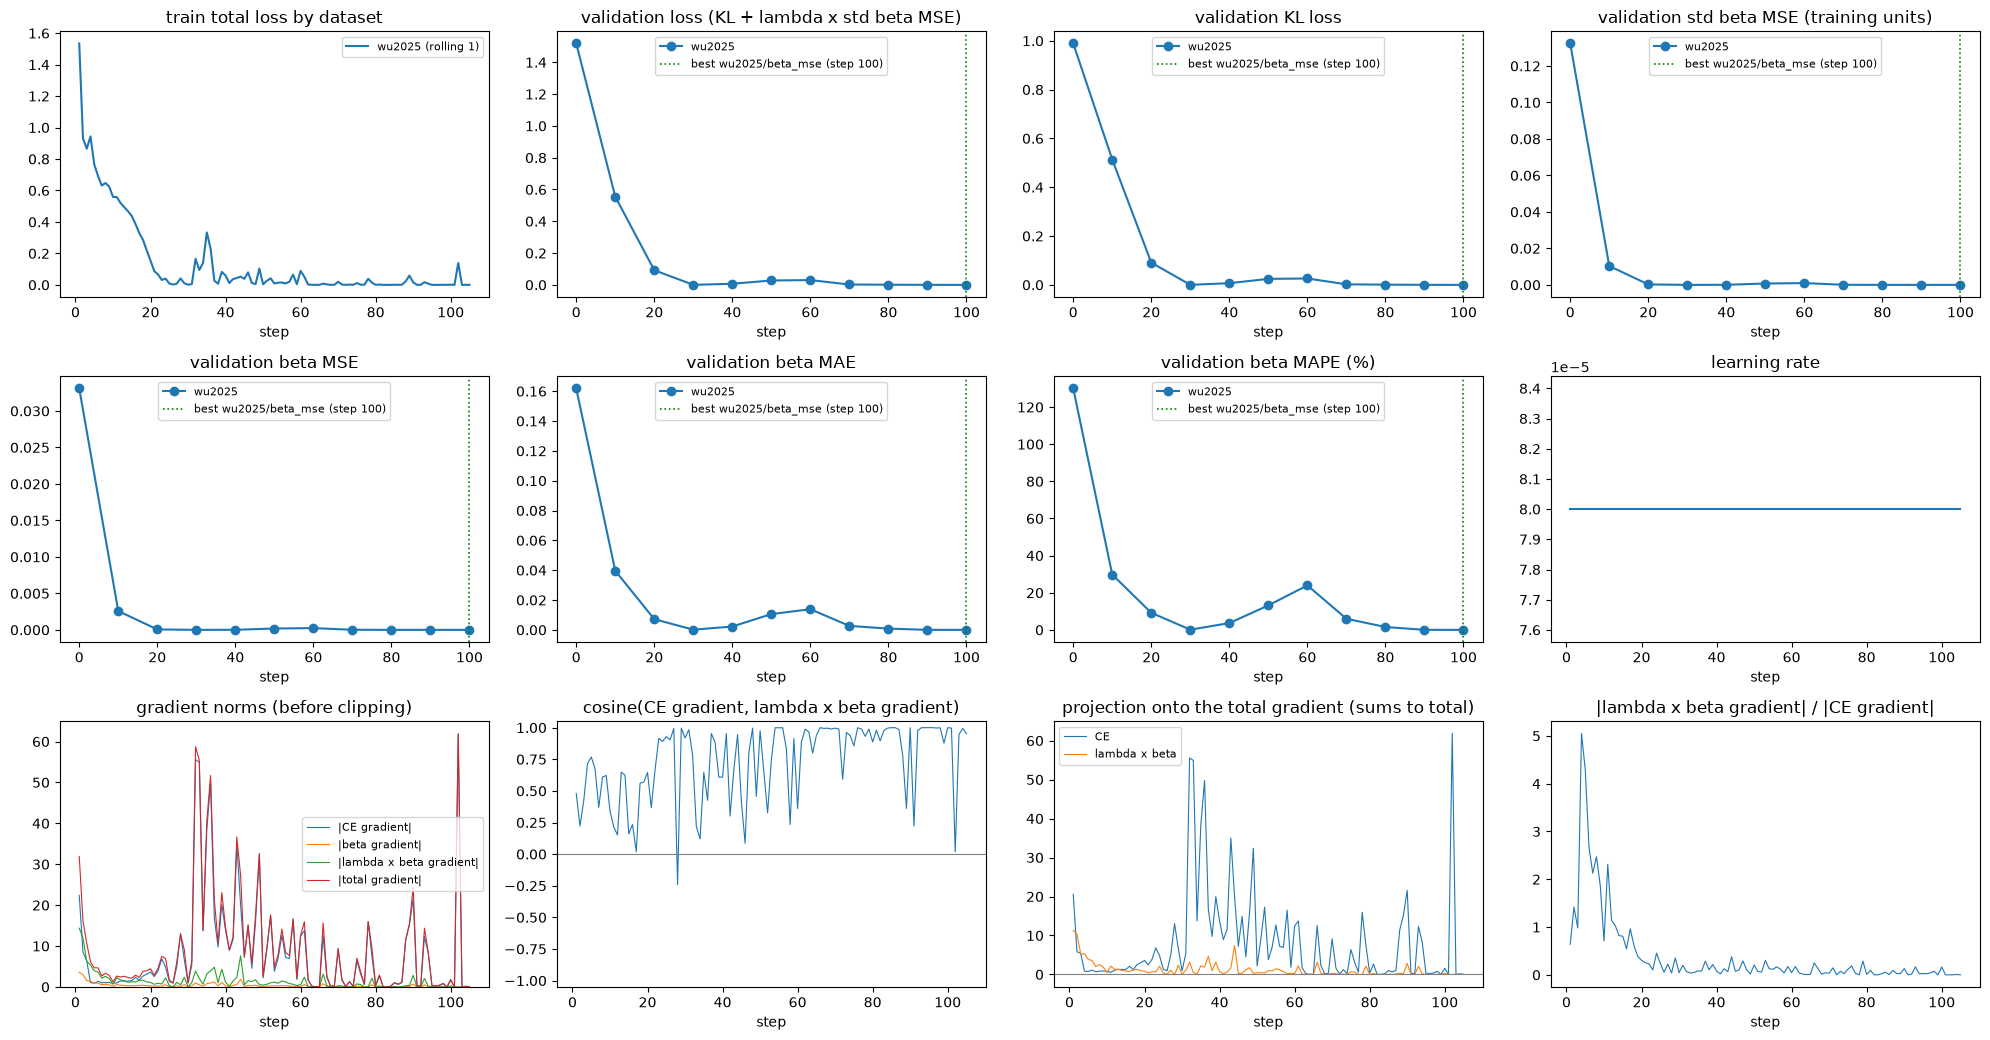

wu2025 | lambda=4:   0%|          | 0/300 [00:00<?, ?it/s]

pass 1 (forward): 0it [00:00, ?it/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

... (3 outputs left out)

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/1 [00:00<?, ?batch/s]

KeyboardInterrupt: 

In [19]:
beta_lambda = 4.0
run_config = replace(BASE_CONFIG, beta_lambda=beta_lambda)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=fixed_items,
    specs_by_dataset=specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

# Compare

In [ ]:
# Every saved run: the fixed sample's training losses per step (train mode) and its validation (eval mode), by lambda
step_dfs = {}
val_dfs = {}
for saved_run_dir in sorted(RUNS_DIR.iterdir()):
    step_dfs[saved_run_dir.name] = pd.read_csv(saved_run_dir / "steps.csv")
    val_dfs[saved_run_dir.name] = pd.read_csv(saved_run_dir / "val_history.csv")

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for name, step_df in step_dfs.items():
    axes[0].plot(step_df["step"], step_df["raw_beta_loss"], linewidth=0.9, label=name)
    axes[1].plot(step_df["step"], step_df["kl_loss"], linewidth=0.9, label=name)
for name, val_df in val_dfs.items():
    axes[2].plot(val_df["step"], val_df[f"{DATASET}/std_beta_mse"], marker="o", markersize=3, label=name)
    axes[3].plot(val_df["step"], val_df[f"{DATASET}/kl_loss"], marker="o", markersize=3, label=name)
axes[0].set_title("training std beta loss (fixed sample, train mode)")
axes[1].set_title("training KL (fixed sample, train mode)")
axes[2].set_title("validation std beta MSE (fixed sample, eval mode)")
axes[3].set_title("validation KL (fixed sample, eval mode)")
for ax in axes:
    ax.set_yscale("log")
    ax.set_xlabel("step")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# The same validation at a few steps, one column per run
TABLE_STEPS = [0, 50, 100, 200, OVERFIT_STEPS]
table_parts = {}
for name, val_df in val_dfs.items():
    indexed = val_df.set_index("step")
    table_parts[(name, "std_beta_mse")] = indexed.loc[TABLE_STEPS, f"{DATASET}/std_beta_mse"]
    table_parts[(name, "kl_loss")] = indexed.loc[TABLE_STEPS, f"{DATASET}/kl_loss"]
display(pd.DataFrame(table_parts).round(5))